Mounted at /content/drive
Dataset extracted to /content/dataset
Device: cuda
Detected 14 classes: ['AK', 'BCC', 'BKL', 'Chickenpox', 'Cowpox', 'DF', 'HFMD', 'Healthy', 'MEL', 'Measles', 'Monkeypox', 'NV', 'SCC', 'VASL']
Using WeightedRandomSampler for training loader.
Train samples: 29322 Val samples: 7334
Class counts (train): Counter({11: 10300, 8: 3617, 10: 3408, 1: 2658, 2: 2099, 6: 1932, 7: 1368, 3: 900, 4: 792, 0: 693, 9: 660, 12: 502, 13: 202, 5: 191})


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Model created: vit_base_patch16_224 drop rates: 0.0 0.0 0.0
Wrapped classifier head with Dropout(0.1)
Head params count: 10766
Backbone params count: 85798656
Starting training for 12 epochs.


Saved best model to: /content/drive/MyDrive/best_vit_inception_replacement.pt
Epoch 1/12 summary: train_loss=0.8869 train_acc=0.7810 val_loss=0.9557 val_acc=0.7401 val_auc=0.9793  time=1096.3s


Saved best model to: /content/drive/MyDrive/best_vit_inception_replacement.pt
Epoch 2/12 summary: train_loss=0.5826 train_acc=0.8995 val_loss=0.7628 val_acc=0.8189 val_auc=0.9830  time=1096.3s


... (7 outputs left out)

Saved best model to: /content/drive/MyDrive/best_vit_inception_replacement.pt
Epoch 10/12 summary: train_loss=0.3490 train_acc=0.9870 val_loss=0.5747 val_acc=0.9040 val_auc=0.9924  time=1095.5s


Saved best model to: /content/drive/MyDrive/best_vit_inception_replacement.pt
Epoch 11/12 summary: train_loss=0.3429 train_acc=0.9893 val_loss=0.5746 val_acc=0.9032 val_auc=0.9920  time=1096.5s


Saved best model to: /content/drive/MyDrive/best_vit_inception_replacement.pt
Epoch 12/12 summary: train_loss=0.3417 train_acc=0.9900 val_loss=0.5709 val_acc=0.9067 val_auc=0.9924  time=1096.3s
Loading best model from: /content/drive/MyDrive/best_vit_inception_replacement.pt



Final Validation Accuracy: 90.67%

Classification Report:
               precision    recall  f1-score   support

          AK       0.79      0.75      0.77       174
         BCC       0.87      0.93      0.90       665
         BKL       0.77      0.83      0.80       525
  Chickenpox       1.00      1.00      1.00       225
      Cowpox       1.00      0.99      0.99       198
          DF       0.89      0.88      0.88        48
        HFMD       1.00      1.00      1.00       483
     Healthy       1.00      1.00      1.00       342
         MEL       0.78      0.79      0.78       905
     Measles       0.99      0.99      0.99       165
   Monkeypox       1.00      1.00      1.00       852
          NV       0.93      0.89      0.91      2575
         SCC       0.80      0.82      0.81       126
        VASL       0.93      1.00      0.96        51

    accuracy                           0.91      7334
   macro avg       0.91      0.92      0.91      7334
weighted avg       0

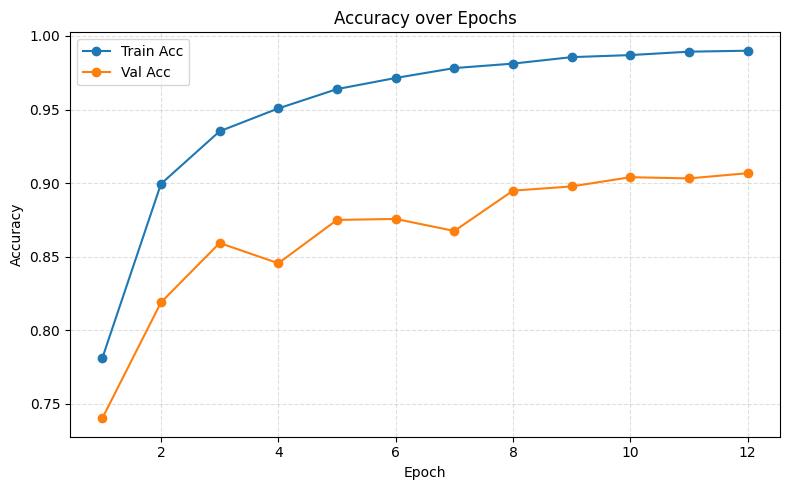

Saved accuracy plot to: /content/drive/MyDrive/diabetic_eye_results/inception_repl_accuracy.png


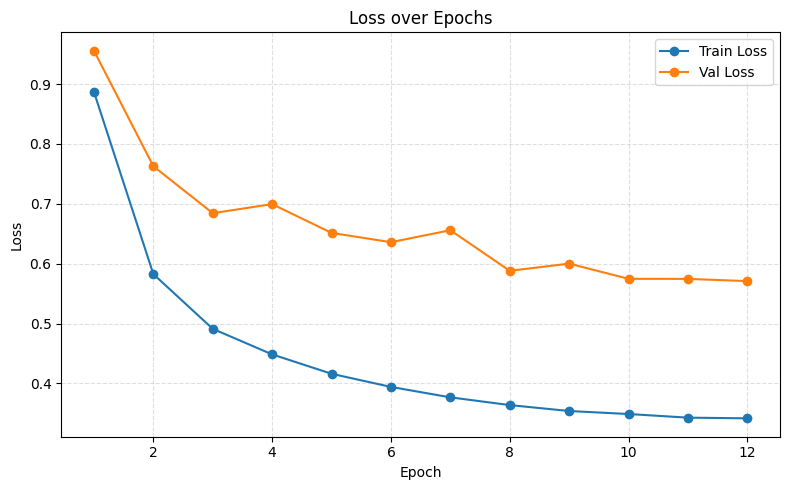

Saved loss plot to: /content/drive/MyDrive/diabetic_eye_results/inception_repl_loss.png


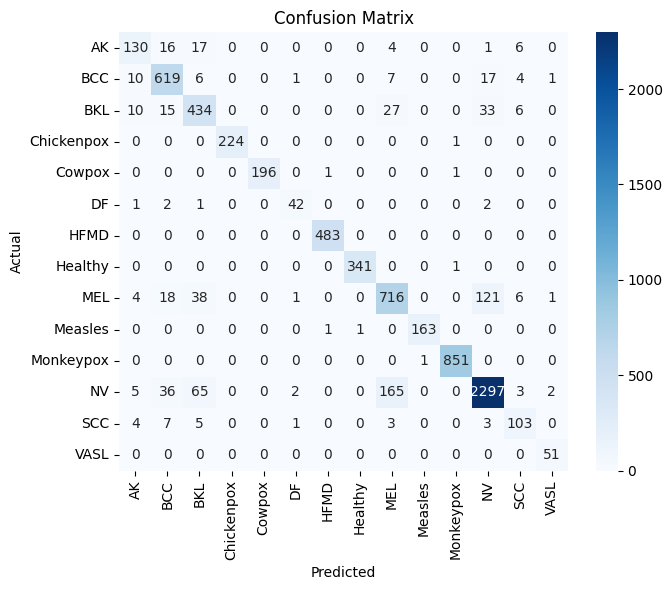

Saved confusion matrix to: /content/drive/MyDrive/diabetic_eye_results/inception_repl_confusion_matrix.png


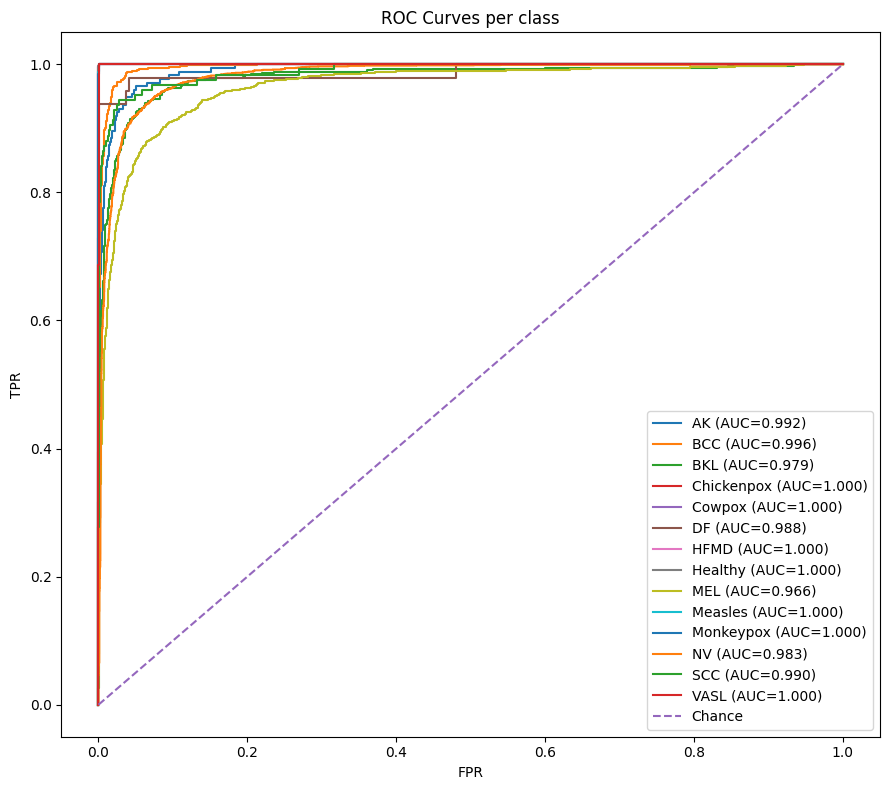

Saved ROC plot to: /content/drive/MyDrive/diabetic_eye_results/inception_repl_roc.png
Saved final model state dict to: /content/drive/MyDrive/final_vit_inception_replacement.pt


In [1]:
# UPDATED: single-phase ViT training — improved/fixed hyperparams & LR groups (no data paths changed)
# Requirements: torch, torchvision, timm, scikit-learn, tqdm, matplotlib, seaborn

import os
import random
import zipfile
import time
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from torchvision import transforms, datasets
import timm
from tqdm import tqdm

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight
from torch.utils.data import WeightedRandomSampler

# ---------------- Configuration (edit as needed) ----------------
DRIVE_MOUNT = True
ZIP_PATH = "/content/drive/MyDrive/n.zip"
EXTRACT_PATH = "/content/dataset"
TRAIN_DIR = "/content/dataset/n/train"
VAL_DIR   = "/content/dataset/n/val"
GRAPH_DIR = "/content/drive/MyDrive/diabetic_eye_results"
CHECKPOINT_PATH = "/content/drive/MyDrive/best_vit_inception_replacement.pt"
FINAL_MODEL_PATH = "/content/drive/MyDrive/final_vit_inception_replacement.pt"

MODEL_NAME = "vit_base_patch16_224"
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2
SEED = 42
EPOCHS = 12
SHOW_GPU_MEM = True

# early stop (overfitting detection)
OVERFIT_THRESHOLD = 0.15
EARLYSTOP_PATIENCE = 3
MIN_EPOCHS_BEFORE_STOP = 5

# Anti-overfitting / training hyperparams (tuned more conservatively)
USE_MIXUP = False             # OFF by default (can enable and tune later)
MIXUP_ALPHA = 0.4
LABEL_SMOOTHING = 0.05       # small smoothing helps stability
RANDOM_ERASE_PROB = 0.03     # lighter random erasing
HEAD_DROPOUT = 0.1           # small head dropout
DROP_RATE = 0.0              # backbone dropouts: keep low for fine-tuning
ATTN_DROP_RATE = 0.0
DROPPATH_RATE = 0.0

# Differential LR groups
BACKBONE_LR = 1e-5
HEAD_LR = 2e-4
WEIGHT_DECAY = 1e-2

# gradient clipping
MAX_GRAD_NORM = 1.0

# optionally balance classes with sampler
USE_WEIGHTED_SAMPLER = True

# ---------------- Reproducibility ----------------
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ---------------- Mount Drive & extract dataset (Colab) ----------------
if DRIVE_MOUNT:
    try:
        from google.colab import drive
        drive.mount('/content/drive', force_remount=False)
    except Exception:
        pass

if os.path.exists(ZIP_PATH) and not os.path.exists(EXTRACT_PATH):
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(EXTRACT_PATH)
        print("Dataset extracted to", EXTRACT_PATH)
else:
    print("Zip not found or dataset already extracted (or already extracted).")

os.makedirs(GRAPH_DIR, exist_ok=True)
os.makedirs(os.path.dirname(CHECKPOINT_PATH), exist_ok=True)

# ---------------- Device & dataset checks ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if not os.path.isdir(TRAIN_DIR) or not os.path.isdir(VAL_DIR):
    raise FileNotFoundError(f"Train/Val directories not found. Expected: {TRAIN_DIR} and {VAL_DIR}")

# ---------------- Class discovery ----------------
classes = sorted([d for d in os.listdir(TRAIN_DIR) if os.path.isdir(os.path.join(TRAIN_DIR, d))])
num_classes = len(classes)
print(f"Detected {num_classes} classes: {classes}")

# ---------------- Transforms ----------------
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.08, contrast=0.08, saturation=0.08, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    transforms.RandomErasing(p=RANDOM_ERASE_PROB, scale=(0.02, 0.33), ratio=(0.3, 3.3), value='random')
])

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# ---------------- Datasets ----------------
train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
val_dataset   = datasets.ImageFolder(VAL_DIR, transform=val_transform)

# ---------------- Weighted sampler (optional) ----------------
if USE_WEIGHTED_SAMPLER:
    labels = [s[1] for s in train_dataset.samples]
    class_counts = np.bincount(labels, minlength=num_classes)
    # avoid zero counts
    class_counts = np.maximum(class_counts, 1)
    class_weights = 1.0 / class_counts
    sample_weights = [class_weights[l] for l in labels]
    sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)
    train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False,
                                               sampler=sampler, num_workers=NUM_WORKERS, pin_memory=True)
    print("Using WeightedRandomSampler for training loader.")
else:
    train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                                               num_workers=NUM_WORKERS, pin_memory=True)

val_loader   = torch.utils.data.DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                                           num_workers=NUM_WORKERS, pin_memory=True)

print("Train samples:", len(train_dataset), "Val samples:", len(val_dataset))
print("Class counts (train):", Counter([s[1] for s in train_dataset.samples]))

# ---------------- Loss (with optional label smoothing) ----------------
if LABEL_SMOOTHING and LABEL_SMOOTHING > 0.0:
    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
else:
    criterion = nn.CrossEntropyLoss()

# ---------------- Model ----------------
model = timm.create_model(MODEL_NAME, pretrained=True, num_classes=num_classes,
                          drop_rate=DROP_RATE, attn_drop_rate=ATTN_DROP_RATE, drop_path_rate=DROPPATH_RATE)
model.to(device)
print("Model created:", MODEL_NAME, "drop rates:", DROP_RATE, ATTN_DROP_RATE, DROPPATH_RATE)

# try to wrap head with dropout (works for common timm ViT)
def wrap_head_with_dropout(m, dropout_p):
    wrapped = False
    try:
        if hasattr(m, "head") and isinstance(m.head, nn.Linear):
            in_f = m.head.in_features
            m.head = nn.Sequential(nn.Dropout(p=dropout_p), nn.Linear(in_f, num_classes))
            wrapped = True
        elif hasattr(m, "classifier") and isinstance(m.classifier, nn.Linear):
            in_f = m.classifier.in_features
            m.classifier = nn.Sequential(nn.Dropout(p=dropout_p), nn.Linear(in_f, num_classes))
            wrapped = True
        else:
            # try to find final linear layer name and replace it
            for name, module in m.named_modules():
                if isinstance(module, nn.Linear) and module.out_features == num_classes:
                    parent_name = name.rpartition('.')[0]
                    # best-effort: don't aggressively replace arbitrary layers
                    # skip replacing if already a Sequential etc.
                    # if we find a plain linear that maps to num_classes, wrap it:
                    # Note: not always necessary; skip if uncertain
                    pass
    except Exception as e:
        print("Head wrap warning:", e)
    return wrapped

wrapped = wrap_head_with_dropout(model, HEAD_DROPOUT)
if wrapped:
    model.to(device)
    print(f"Wrapped classifier head with Dropout({HEAD_DROPOUT})")
else:
    print("Classifier head left as-is (no simple linear head detected to wrap).")

# Make whole model trainable but use differential LR below
for p in model.parameters():
    p.requires_grad = True

# ---------------- Build differential LR optimizer ----------------
# attempt to collect head params explicitly
head_param_ids = set()
head_params = []
backbone_params = []

# common attribute names to check
if hasattr(model, "head"):
    for p in model.head.parameters():
        head_param_ids.add(id(p))
if hasattr(model, "classifier"):
    for p in model.classifier.parameters():
        head_param_ids.add(id(p))

# fallback: look for parameters with 'head'/'classifier' in name
for name, p in model.named_parameters():
    if ("head" in name) or ("classifier" in name) or name.endswith(".fc.weight") or name.endswith(".fc.bias"):
        head_param_ids.add(id(p))

# split params
for p in model.parameters():
    if id(p) in head_param_ids:
        head_params.append(p)
    else:
        backbone_params.append(p)

print("Head params count:", sum(p.numel() for p in head_params))
print("Backbone params count:", sum(p.numel() for p in backbone_params))

optimizer = AdamW([
    {"params": backbone_params, "lr": BACKBONE_LR},
    {"params": head_params,     "lr": HEAD_LR}
], weight_decay=WEIGHT_DECAY)

# scheduler: cosine annealing over epoch budget
scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-7)

# ---------------- Utilities ----------------
def human_gpu_mem():
    if not torch.cuda.is_available() or not SHOW_GPU_MEM:
        return ""
    return f"{torch.cuda.memory_reserved(device)/1024**3:.2f}GB"

def compute_metrics_all(y_true_list, y_pred_list, y_prob_array, class_names):
    y_true = np.array(y_true_list)
    y_pred = np.array(y_pred_list)
    acc = accuracy_score(y_true, y_pred)
    report = classification_report(y_true, y_pred, target_names=class_names, zero_division=0)
    n_classes = len(class_names)
    y_true_bin = label_binarize(y_true, classes=list(range(n_classes)))
    if y_true_bin.ndim == 1:
        y_true_bin = y_true_bin.reshape(-1, 1)
    if y_true_bin.shape[1] == 1:
        y_true_bin = np.hstack([1 - y_true_bin, y_true_bin])
    fpr, tpr, roc_auc = {}, {}, {}
    aucs = []
    missing = []
    for i in range(n_classes):
        if np.sum(y_true_bin[:, i]) == 0:
            missing.append(class_names[i])
            continue
        try:
            fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_prob_array[:, i])
            roc_auc[i] = auc(fpr[i], tpr[i])
            aucs.append(roc_auc[i])
        except Exception:
            missing.append(class_names[i])
    macro_auc = np.mean(aucs) if len(aucs) > 0 else 0.0
    return acc, report, roc_auc, fpr, tpr, macro_auc, missing

# ---------------- Train/Validate functions ----------------
def train_one_epoch(model, loader, optimizer, device, epoch, total_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    pbar = tqdm(enumerate(loader, start=1), total=len(loader),
                desc=f"Train {epoch}/{total_epochs}", ncols=120, leave=False)
    for batch_idx, (imgs, labels) in pbar:
        imgs = imgs.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()

        if USE_MIXUP:
            # Keep simple: apply mixup if enabled (but OFF by default)
            lam = np.random.beta(MIXUP_ALPHA, MIXUP_ALPHA) if MIXUP_ALPHA > 0 else 1
            index = torch.randperm(imgs.size(0)).to(device)
            mixed_imgs = lam * imgs + (1 - lam) * imgs[index]
            logits = model(mixed_imgs)
            loss = lam * criterion(logits, labels) + (1 - lam) * criterion(logits, labels[index])
            # approximate preds for monitoring (not perfect under mixup)
            preds = logits.argmax(dim=1)
            # approximate batch acc (not reliable) — don't use for early-stop decision when mixup on
            batch_acc = (lam * (preds == labels).sum().item() + (1 - lam) * (preds == labels[index]).sum().item()) / imgs.size(0)
        else:
            logits = model(imgs)
            loss = criterion(logits, labels)
            preds = logits.argmax(dim=1)
            batch_acc = (preds == labels).float().mean().item()

        loss.backward()

        if MAX_GRAD_NORM and MAX_GRAD_NORM > 0.0:
            torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)

        optimizer.step()

        running_loss += loss.item() * imgs.size(0)
        correct += (preds == labels).sum().item() if not USE_MIXUP else (preds == labels).sum().item()  # conservative
        total += imgs.size(0)
        running_epoch_loss = running_loss / total
        running_epoch_acc = correct / total if total > 0 else 0.0

        postfix = {
            "b_loss": f"{loss.item():.4f}",
            "b_acc": f"{batch_acc:.3f}",
            "e_loss": f"{running_epoch_loss:.4f}",
            "e_acc": f"{running_epoch_acc:.3f}"
        }
        if torch.cuda.is_available() and SHOW_GPU_MEM:
            postfix["GPU"] = human_gpu_mem()
        pbar.set_postfix(postfix, refresh=False)
    pbar.close()
    return running_loss / len(loader.dataset), correct / total if total > 0 else 0.0

def validate(model, loader, device, epoch=None):
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_labels = []
    all_probs = []
    pbar = tqdm(enumerate(loader, start=1), total=len(loader),
                desc=f"Val {epoch}" if epoch else "Val", ncols=120, leave=False)
    with torch.no_grad():
        for batch_idx, (imgs, labels) in pbar:
            imgs = imgs.to(device)
            labels = labels.to(device)
            logits = model(imgs)
            loss = criterion(logits, labels)
            running_loss += loss.item() * imgs.size(0)
            probs = F.softmax(logits, dim=1).cpu().numpy()
            preds = np.argmax(probs, axis=1)
            all_probs.append(probs)
            all_preds.extend(list(preds))
            all_labels.extend(list(labels.cpu().numpy()))
            batch_acc = (preds == labels.cpu().numpy()).mean()
            running_epoch_loss = running_loss / (len(all_labels) if len(all_labels) > 0 else 1)
            running_epoch_acc = accuracy_score(all_labels, all_preds) if len(all_labels) > 0 else 0.0
            postfix = {
                "b_loss": f"{loss.item():.4f}",
                "b_acc": f"{batch_acc:.3f}",
                "e_loss": f"{running_epoch_loss:.4f}",
                "e_acc": f"{running_epoch_acc:.3f}"
            }
            if torch.cuda.is_available() and SHOW_GPU_MEM:
                postfix["GPU"] = human_gpu_mem()
            pbar.set_postfix(postfix, refresh=False)
    pbar.close()
    val_loss = running_loss / len(loader.dataset)
    all_probs = np.vstack(all_probs) if all_probs else np.zeros((0, num_classes))
    return val_loss, all_labels, all_preds, all_probs

# ---------------- Training loop ----------------
history = {"train_loss":[], "train_acc":[], "val_loss":[], "val_acc":[], "val_auc_macro":[]}
best_val_loss = float('inf')
best_auc_macro = 0.0
total_epochs = EPOCHS

overfit_counter = 0
print("Starting training for", total_epochs, "epochs.")
for epoch in range(1, total_epochs + 1):
    t0 = time.time()
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, device, epoch, total_epochs)
    val_loss, y_true_val, y_pred_val, y_prob_val = validate(model, val_loader, device, epoch)
    _, _, _, _, _, val_auc_macro, _ = compute_metrics_all(y_true_val, y_pred_val, y_prob_val, classes)

    # step scheduler per-epoch
    scheduler.step()

    history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss); history["val_acc"].append(accuracy_score(y_true_val, y_pred_val))
    history["val_auc_macro"].append(val_auc_macro)

    # Save best model
    if val_loss < best_val_loss or val_auc_macro > best_auc_macro:
        best_val_loss = min(best_val_loss, val_loss)
        best_auc_macro = max(best_auc_macro, val_auc_macro)
        torch.save(model.state_dict(), CHECKPOINT_PATH)
        print("Saved best model to:", CHECKPOINT_PATH)

    acc_gap = train_acc - history["val_acc"][-1]
    if acc_gap > OVERFIT_THRESHOLD:
        overfit_counter += 1
        print(f"Warning: epoch {epoch} train-val acc gap = {acc_gap:.3f} (counter {overfit_counter}/{EARLYSTOP_PATIENCE})")
    else:
        overfit_counter = 0

    print(f"Epoch {epoch}/{total_epochs} summary: train_loss={train_loss:.4f} train_acc={train_acc:.4f} "
          f"val_loss={val_loss:.4f} val_acc={history['val_acc'][-1]:.4f} val_auc={val_auc_macro:.4f}  time={time.time()-t0:.1f}s")

    if epoch >= MIN_EPOCHS_BEFORE_STOP and overfit_counter >= EARLYSTOP_PATIENCE:
        print(f"Early stopping triggered at epoch {epoch} due to sustained train-val accuracy gap > {OVERFIT_THRESHOLD}")
        break

# ---------------- Final evaluation ----------------
print("Loading best model from:", CHECKPOINT_PATH)
model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=device))
model.to(device)
model.eval()

val_loss, y_true_val, y_pred_val, y_prob_val = validate(model, val_loader, device, epoch="final")
acc, report, roc_auc_dict, fpr_dict, tpr_dict, macro_auc, missing = compute_metrics_all(y_true_val, y_pred_val, y_prob_val, classes)
print("\nFinal Validation Accuracy: {:.2f}%".format(acc * 100))
print("\nClassification Report:\n", report)
print("Macro AUC (mean of available class AUCs):", macro_auc)
if missing:
    print("Skipped ROC for classes (no positive samples):", missing)

# ---------------- Save plots ----------------
os.makedirs(GRAPH_DIR, exist_ok=True)
epochs_range = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8,5))
plt.plot(epochs_range, history["train_acc"], marker='o', label='Train Acc')
plt.plot(epochs_range, history["val_acc"], marker='o', label='Val Acc')
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("Accuracy over Epochs"); plt.grid(True, linestyle='--', alpha=0.4); plt.legend()
acc_path = os.path.join(GRAPH_DIR, "inception_repl_accuracy.png")
plt.tight_layout(); plt.savefig(acc_path, dpi=150); plt.show()
print("Saved accuracy plot to:", acc_path)

plt.figure(figsize=(8,5))
plt.plot(epochs_range, history["train_loss"], marker='o', label='Train Loss')
plt.plot(epochs_range, history["val_loss"], marker='o', label='Val Loss')
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Loss over Epochs"); plt.grid(True, linestyle='--', alpha=0.4); plt.legend()
loss_path = os.path.join(GRAPH_DIR, "inception_repl_loss.png")
plt.tight_layout(); plt.savefig(loss_path, dpi=150); plt.show()
print("Saved loss plot to:", loss_path)

cm = confusion_matrix(y_true_val, y_pred_val, labels=list(range(num_classes)))
plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix"); plt.tight_layout()
cm_path = os.path.join(GRAPH_DIR, "inception_repl_confusion_matrix.png")
plt.savefig(cm_path, dpi=150); plt.show()
print("Saved confusion matrix to:", cm_path)

plt.figure(figsize=(9,8))
plotted = False
for i in range(num_classes):
    if i in roc_auc_dict:
        plt.plot(fpr_dict[i], tpr_dict[i], label=f"{classes[i]} (AUC={roc_auc_dict[i]:.3f})"); plotted = True
plt.plot([0,1],[0,1], linestyle='--', label='Chance')
if plotted:
    plt.title("ROC Curves per class"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend(loc='lower right')
    roc_path = os.path.join(GRAPH_DIR, "inception_repl_roc.png"); plt.tight_layout(); plt.savefig(roc_path, dpi=150); plt.show()
    print("Saved ROC plot to:", roc_path)
else:
    print("No ROC curves plotted (no positive samples for some classes).")

# ---------------- Save final model ----------------
torch.save(model.state_dict(), FINAL_MODEL_PATH)
print("Saved final model state dict to:", FINAL_MODEL_PATH)
